# CTR modelling with continuous epitaxy interfaces

This executable example demonstrates the corrected **cyclic upper anchor** and
**fixed lower-lattice registration** in `EpitaxyInterface`. It builds a complete
bulk → interface → Film → sharp Poisson surface model, then checks geometry,
complex structure factors, and electron-density profiles.

The C/Si cells below are deliberately simple **synthetic layered structures**, not
crystallographic models of diamond carbon or silicon, and no experimental data
are fitted. Their contrasting scattering factors make interface changes visible.
No external structure files or test-module imports are needed.

Run **Restart Kernel and Run All** with the corrected orGUI checkout and its
scientific Python dependencies, plus Matplotlib, pandas, and an IPython kernel.
Figures use the inline backend and remain visible in the saved notebook.

You will see:
1. A model and its CTR/density curves for three strain couplings.
2. Stable Film layer counts at zero skew, including a reversed cycle.
3. Continuous geometry across the former three-layer `S = 2/3` jump.
4. Complex-amplitude and density differences tending to zero with perturbation.
5. Tail-support convergence for an unequal-spacing, explicitly rotated cycle.

In [2]:
%matplotlib inline
from pathlib import Path
import copy
import os
import sys

# Windows conda kernels may need their environment's DLL directory explicitly.
# Keep the handle alive for the kernel lifetime; other platforms need no change.
_conda_dll_dir = Path(sys.prefix) / "Library" / "bin"
if sys.platform == "win32" and _conda_dll_dir.is_dir():
    os.environ["PATH"] = str(_conda_dll_dir) + os.pathsep + os.environ.get("PATH", "")
    _conda_dll_handle = os.add_dll_directory(str(_conda_dll_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

repository_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "orgui" / "datautils").is_dir()), None
)
#if repository_root is not None:
#    sys.path.insert(0, str(repository_root))

from orgui.datautils.xrayutils import CTRcalc, CTRfilm, CTRuc
from orgui.datautils.xrayutils.CTRdistributions import PoissonProfile, SkellamProfile

#if repository_root is not None and repository_root not in Path(CTRcalc.__file__).resolve().parents:
#    raise RuntimeError("Restart the kernel: a different installed orGUI is already loaded.")

plt.rcParams.update({
    "figure.dpi": 115, "font.size": 11, "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.fontsize": 9, "axes.grid": True, "grid.alpha": 0.18,
})
COLORS = ["#0072B2", "#D55E00", "#009E73"]
STYLES = ["-", "--", ":"]
print("orGUI module:", CTRcalc.__file__)
print("CTR backend:", CTRuc.CTR_ACCEL_BACKEND)

orGUI module: C:\Users\timof\miniforge3\Lib\site-packages\orgui\datautils\xrayutils\CTRcalc.py
CTR backend: cpp


## 1. Define a model with explicit units and layer boundaries

| Input | Meaning |
|---|---|
| `positions` | Native fractional normal coordinates of structural-layer boundaries |
| `repeat_A` | Lower normal repeat in Å; lateral lattice constants are 3 Å |
| `interface_width` | Skellam width in unit cells; standard deviation is `N * width` structural intervals |
| `skew` | Dimensionless asymmetry in `[-1, 1]`; mean is `width**2 * N**2 * skew` intervals |
| `film_width` | Nominal Film width in **structural layers**, not unit cells |
| `coupling` | 0: independent lattices; 1: fully coupled normal displacement field |
| `mismatch` | Upper/lower normal-repeat ratio; lateral lattice constants stay equal |
| `offset` | Upper registry offset in lower-repeat fractional units, so `offset * repeat_A` is in Å |
| `energy_eV` | Photon energy passed to the CTR API in **eV** |

`layerpos` is assigned explicitly; adding atoms alone does not establish the
intended layer intervals. Both live parameters and their fixed baselines are
initialized. Only skew is registered as a fit parameter, so `setParameters`
demonstrates the same update path used during fitting.

`F_bulk` includes native repeat zero. Thus the positive-origin bulk used here
already contains the atoms in that repeat; the interface must subtract the
actual supplied sites. Do not assume its sharp termination is at absolute z=0.

In [3]:
def make_cell(name, element, repeat_A, positions):
    """Create one synthetic atom per layer with fractional native coordinates."""
    cell = CTRcalc.UnitCell([3.0, 3.0, repeat_A], [90.0] * 3, name=name)
    for layer_id, z_fraction in enumerate(positions, start=1):
        cell.addAtom(element, [0.0, 0.0, z_fraction], 0.1, 0.1, 1.0, layer=layer_id)
        cell.layerpos[float(layer_id)] = float(z_fraction)
    return cell


def make_model(film_width=32.25, interface_width=0.5, coupling=1.0,
               mismatch=1.0, offset=0.0, reverse=False, registry_layers=None,
               positions=(0.0, 1 / 3, 2 / 3), tail_probability=1e-10,
               transition=None, repeat_A=6.58069633, energy_eV=18000.0):
    """Build a kinematic CTR model; widths and units are listed above."""
    bulk = make_cell("bulk", "C", repeat_A, positions)
    if reverse:
        bulk = bulk.translate_layered([0, 0, -1])
    top = make_cell("top", "Si", repeat_A * mismatch, positions)
    bottom = make_cell("bottom", "C", repeat_A, positions)
    interface = CTRfilm.EpitaxyInterface(
        top, bottom, name="interface", layer_transition=transition,
        profile=SkellamProfile(interface_width, tail_probability=tail_probability),
    )
    interface.basis[:] = [interface_width, 0.0, coupling, offset]
    interface.basis_0[:] = interface.basis
    interface.addFitParameter("S", limits=(-1.0, 1.0))
    film = CTRfilm.Film(copy.deepcopy(top), name="film")
    film.basis[:] = film.basis_0[:] = film_width
    surface = CTRfilm.PoissonSurface(
        copy.deepcopy(top), profile=PoissonProfile(0.0), name="surface",
    )
    components = [interface, film, surface]
    if registry_layers is not None:
        registry = CTRfilm.Film(copy.deepcopy(bulk), name="registry")
        registry.basis[:] = registry.basis_0[:] = registry_layers
        components.insert(0, registry)
    model = CTRcalc.SXRDCrystal(
        bulk, *components, stacking=np.arange(1, len(components) + 1), atten=0.01,
    )
    model.setEnergy(energy_eV)
    return model


def set_skew(model, skew):
    """Apply the fitted skew and regenerate the stack without changing Film W."""
    model.setParameters([float(skew)])
    model.apply_stacking()
    return model


def geometry(model):
    """Return absolute boundary heights in Å and the generated Film layer count."""
    interface, film = model["interface"], model["film"]
    count = sum(len(layer.coherentDomainMatrix) for layer in film.layer_ucs)
    np.testing.assert_allclose(film.pos_absolute, interface.height_absolute, atol=1e-9)
    return {
        "remaining Film layers": count,
        "interface top (Å)": interface.height_absolute,
        "Film width origin (Å)": interface.stacking_loc_absolute,
        "Film top (Å)": film.height_absolute,
    }


def sample(model, skew, h, k, ell, z_A):
    """Evaluate complex F (electrons) and real density (electrons/Å³) on fixed grids."""
    set_skew(model, skew)
    return geometry(model), model.F(h, k, ell), model.zDensity_G(z_A, 0.0, 0.0).real


L = np.linspace(0.13, 3.87, 650)  # Reference bulk reciprocal-lattice units.
H = np.zeros_like(L)
K = np.zeros_like(L)
z_A = np.linspace(-30.0, 130.0, 6401)

The first comparison uses a 10% normal-repeat mismatch, a 0.15-repeat offset,
and skew 0.35. These are real model changes: the different coupling curves
**should not coincide**. Curves use their absolute calculated scale, without
vertical offsets or independent normalization.

The plotted CTR quantity is kinematic $|F_{00L}|^2$ in electrons² per reference
lateral cell, not detector counts or a calibrated reflectivity. The real part
of `zDensity_G` is plotted on the right; its imaginary part contains absorptive
contrast. Density is shown around the interface, while the table reports the
complete Film geometry. Bulk attenuation is 0.01 per reference repeat and is
held fixed throughout this notebook.

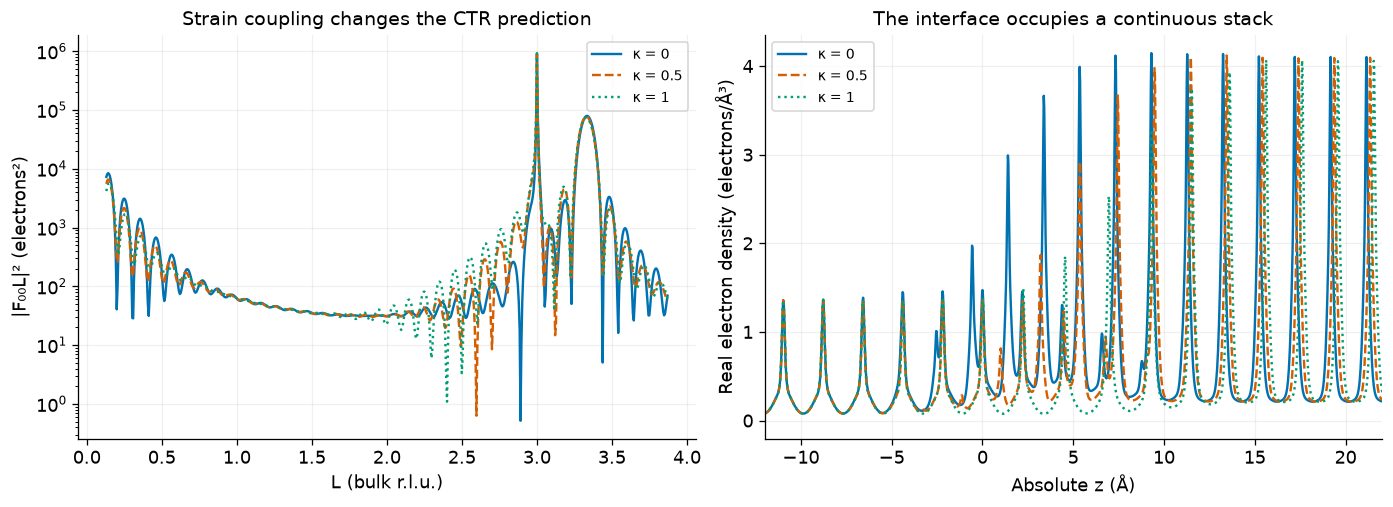

,coupling κ,remaining Film layers,interface top (Å),Film width origin (Å),Film top (Å)
0,0.0,15,34.968175,0.987104,64.581309
1,0.5,15,39.122240,5.141169,68.735373
2,1.0,15,43.276304,9.295234,72.889438


In [4]:
overview = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout="constrained")
for coupling, color, style in zip([0.0, 0.5, 1.0], COLORS, STYLES):
    model = make_model(coupling=coupling, mismatch=0.9, offset=0.15)
    row, amplitude, density = sample(model, 0.35, H, K, L, z_A)
    overview.append({"coupling κ": coupling, **row})
    label = f"κ = {coupling:g}"
    axes[0].semilogy(L, np.abs(amplitude) ** 2, style, color=color, label=label)
    axes[1].plot(z_A, density, style, color=color, label=label)
axes[0].set(xlabel="L (bulk r.l.u.)", ylabel="|F₀₀L|² (electrons²)",
            title="Strain coupling changes the CTR prediction")
axes[1].set(xlabel="Absolute z (Å)", ylabel="Real electron density (electrons/Å³)",
            xlim=(-12, 22), title="The interface occupies a continuous stack")
for ax in axes:
    ax.legend()
plt.show()
display(pd.DataFrame(overview).round(6))

## 2. A cyclic rotation must not remove a Film repeat at zero skew

The original upper-anchor issue appeared in the two-layer reversed cycle.
Here the interface width is 0.15 cells, repeats are matched, coupling is one,
and the offset is zero. We reproduce nominal Film widths 17, 18, and 32.

The anchor must transform a native point inside the **actual ordered layer
interval**, including the cycle's registry offset. Layer IDs are labels, not
distances. At $S=-10^{-8},0,+10^{-8}$ the generated Film count must stay fixed,
and Film height must approach the same value from both sides.

In [5]:
zero_rows = []
for reverse in (False, True):
    for width in (17, 18, 32):
        model = make_model(film_width=width, interface_width=0.15,
                           positions=(0.0, 0.5), reverse=reverse)
        values = [geometry(set_skew(model, s)) for s in (-1e-8, 0.0, 1e-8)]
        counts = [item["remaining Film layers"] for item in values]
        heights = [item["Film top (Å)"] for item in values]
        assert counts == [width - 6] * 3
        assert np.ptp(heights) < 1e-9
        zero_rows.append({
            "cycle": tuple(int(x) for x in model["interface"].layer_order),
            "nominal Film W": width, "count at −ε": counts[0],
            "count at zero": counts[1], "count at +ε": counts[2],
            "height spread (Å)": np.ptp(heights),
        })
display(pd.DataFrame(zero_rows))
print("PASS: all three widths retain their Film layers in both cyclic orders.")

,cycle,nominal Film W,count at −ε,count at zero,count at +ε,height spread (Å)
0,"(1, 2)",17,11,11,11,0.0
1,"(1, 2)",18,12,12,12,0.0
2,"(1, 2)",32,26,26,26,0.0
3,"(2, 1)",17,11,11,11,0.0
4,"(2, 1)",18,12,12,12,0.0
5,"(2, 1)",32,26,26,26,0.0


PASS: all three widths retain their Film layers in both cyclic orders.


## 3. The lower lattice stays registered across S = 2/3

For three uniform layers and interface width 0.5, the Skellam mean is
$\mu_1-\mu_2=2.25S$. At $S=2/3$ it crosses 1.5 structural intervals, a former
nearest-repeat rounding threshold. The lower reference now comes from the
underlying material, independently of this mean. Subtraction removes the actual
occupied source domains; it never switches because a probability crosses 50%.

Use **Film W = 32.25** to stay away from an unrelated integer layer-count rounding
tie. Film width remains nominal structural layers: its origin is
`stacking_loc_absolute`, whereas its generated layers start at
`stacking_height_absolute`. A moving nominal origin is therefore compatible with
a stationary physical boundary. For unequal intervals W does not specify an
exact physical thickness.

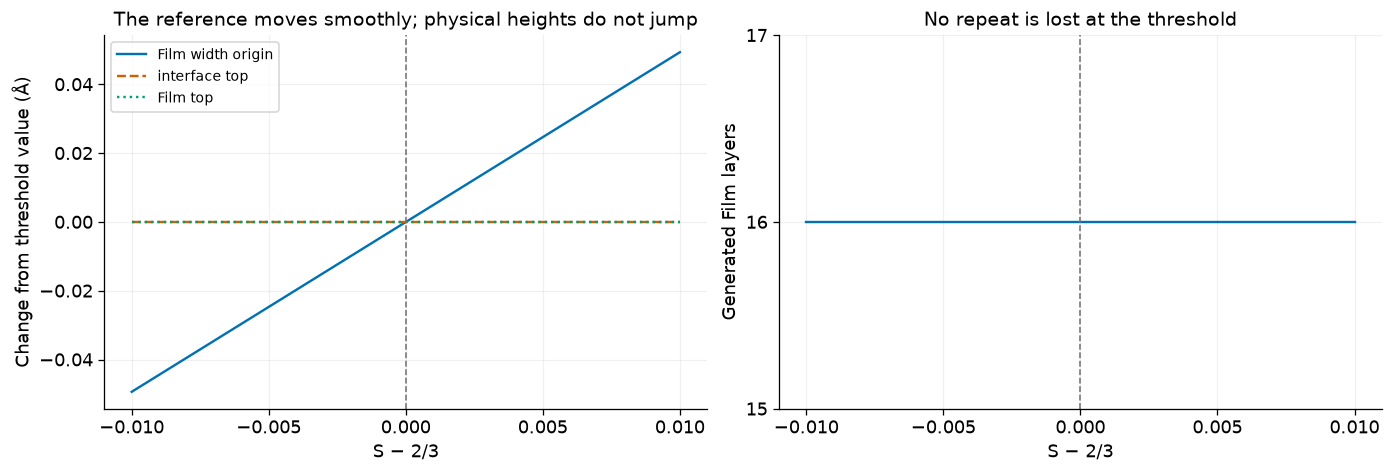

,skew S,remaining Film layers,interface top (Å),Film width origin (Å),Film top (Å)
0,0.656667,16,46.064874,9.821689,81.161921
1,0.666667,16,46.064874,9.871044,81.161921
2,0.676667,16,46.064874,9.920400,81.161921


In [6]:
threshold = 2 / 3
threshold_model = make_model()
center = geometry(set_skew(threshold_model, threshold))
skew_grid = threshold + np.linspace(-0.01, 0.01, 51)
sweep = pd.DataFrame([
    {"skew S": s, **geometry(set_skew(threshold_model, s))} for s in skew_grid
])
assert sweep["remaining Film layers"].nunique() == 1
assert int(sweep["remaining Film layers"].iloc[0]) == 16

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), layout="constrained")
for key, color, style in zip(
    ["Film width origin (Å)", "interface top (Å)", "Film top (Å)"], COLORS, STYLES
):
    axes[0].plot(sweep["skew S"] - threshold, sweep[key] - center[key],
                 style, color=color, label=key.replace(" (Å)", ""))
axes[0].set(xlabel="S − 2/3", ylabel="Change from threshold value (Å)",
            title="The reference moves smoothly; physical heights do not jump")
axes[0].legend()
axes[1].step(sweep["skew S"] - threshold, sweep["remaining Film layers"],
             where="mid", color=COLORS[0])
axes[1].set(xlabel="S − 2/3", ylabel="Generated Film layers", ylim=(15, 17),
            yticks=[15, 16, 17], title="No repeat is lost at the threshold")
for ax in axes:
    ax.set_xticks([-0.01, -0.005, 0, 0.005, 0.01])
    ax.axvline(0, color="0.45", linewidth=1, linestyle="--")
plt.show()
display(sweep.iloc[[0, 25, 50]].round(8).reset_index(drop=True))

### CTR and density on both sides of the threshold

The nearby curves below should nearly overlap. The difference panel exposes a
small, finite response instead of hiding it by normalization. The next section
tests **complex F**, so phase discontinuities cannot be concealed by plotting
intensity alone. All evaluations use identical absolute z and reciprocal-space
grids; no coordinate recentering or curve alignment is applied.

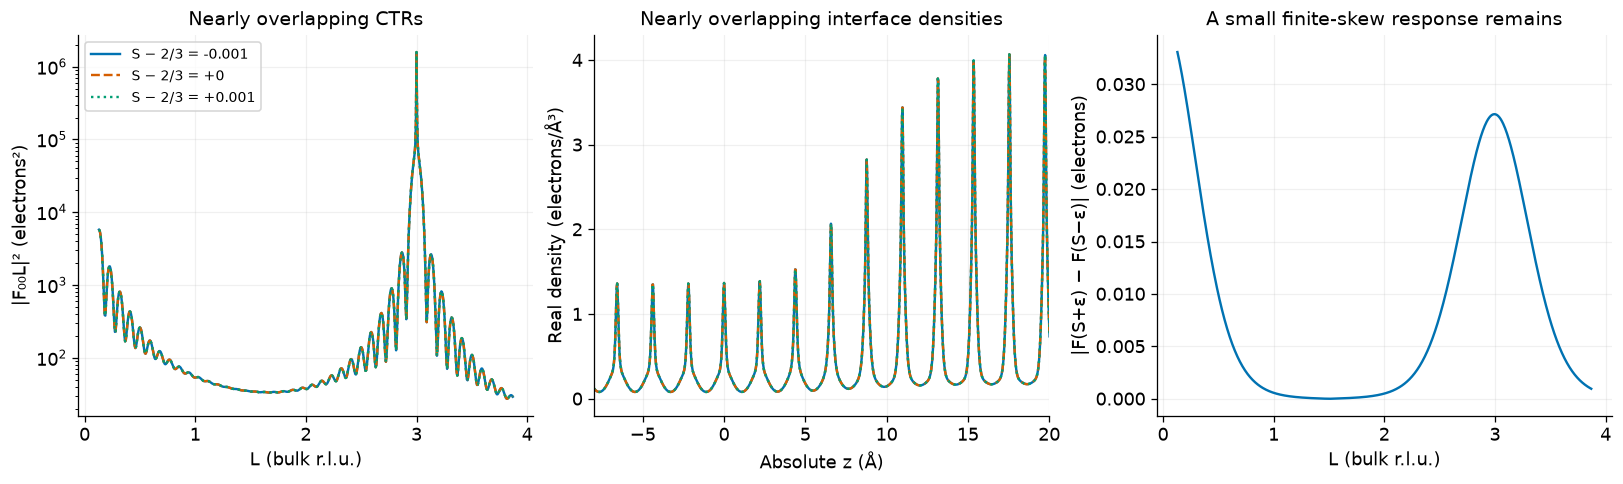

In [7]:
epsilon_plot = 1e-3
nearby = [sample(threshold_model, threshold + ds, H, K, L, z_A)
          for ds in (-epsilon_plot, 0.0, epsilon_plot)]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.1), layout="constrained")
for ds, result, color, style in zip(
    (-epsilon_plot, 0.0, epsilon_plot), nearby, COLORS, STYLES
):
    label = f"S − 2/3 = {ds:+g}"
    axes[0].semilogy(L, np.abs(result[1]) ** 2, style, color=color, label=label)
    axes[1].plot(z_A, result[2], style, color=color)
axes[2].plot(L, np.abs(nearby[2][1] - nearby[0][1]), color=COLORS[0])
axes[0].set(xlabel="L (bulk r.l.u.)", ylabel="|F₀₀L|² (electrons²)", title="Nearly overlapping CTRs")
axes[0].legend()
axes[1].set(xlabel="Absolute z (Å)", ylabel="Real density (electrons/Å³)",
            xlim=(-8, 20), title="Nearly overlapping interface densities")
axes[2].set(xlabel="L (bulk r.l.u.)", ylabel="|F(S+ε) − F(S−ε)| (electrons)",
            title="A small finite-skew response remains")
plt.show()

## 4. Quantify convergence, including phase and exact-threshold agreement

For the reversed two-layer zero-skew case and the three-layer threshold case,
shrink ε from $10^{-3}$ to $10^{-10}$. Compare the maximum complex-F difference
on the `(0,0,L)`, `(1,0,L)`, and `(2,0,L)` rods, and the maximum real-density
difference on a fixed absolute-z diagnostic grid. The geometry metric includes
both physical heights and the Film width origin.

A fixed artificial jump would plateau as ε decreases. A continuous response
decreases approximately linearly until floating-point noise dominates. Exact
threshold results must agree with both limits; they are checked separately.
These are sampled diagnostics, not a proof over every possible model or rod.

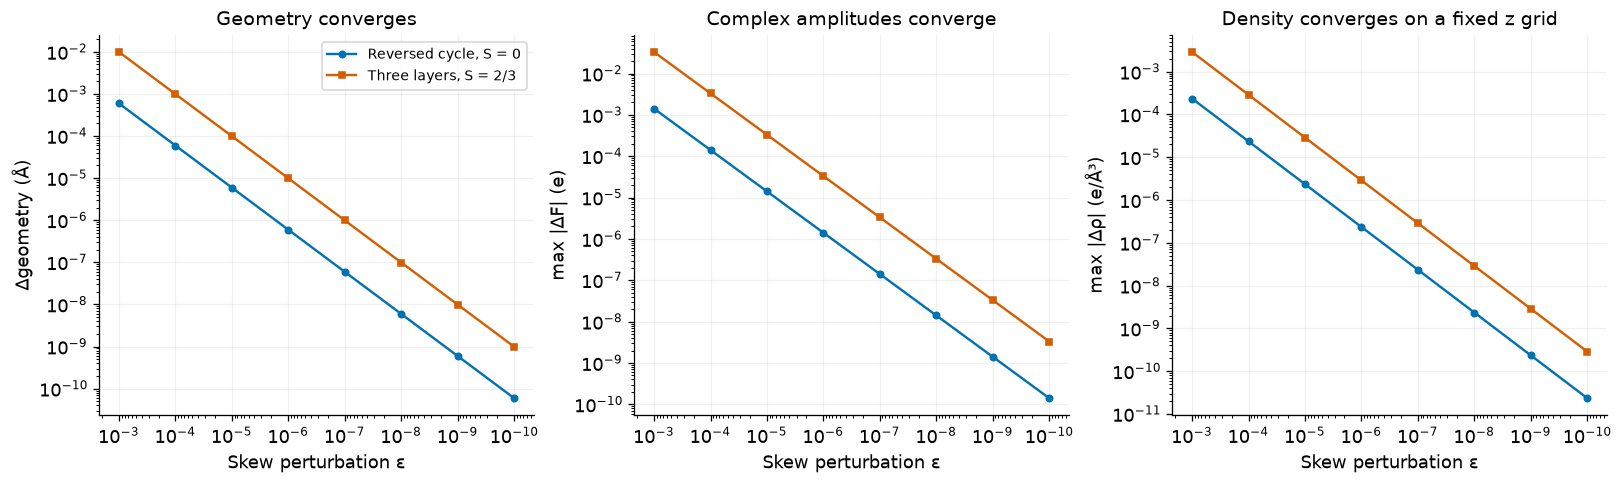

,case,epsilon,Δgeometry (Å),max |ΔF| (e),max |Δρ| (e/Å³)
0,"Reversed cycle, S = 0",1.000000e-03,5.922627e-04,1.410032e-03,2.341391e-04
1,"Reversed cycle, S = 0",1.000000e-06,5.922627e-07,1.410032e-06,2.341391e-07
2,"Reversed cycle, S = 0",1.000000e-10,5.922729e-11,1.410027e-10,2.341372e-11
3,"Three layers, S = 2/3",1.000000e-03,9.871044e-03,3.307265e-02,2.870504e-03
4,"Three layers, S = 2/3",1.000000e-06,9.871044e-06,3.307265e-05,2.870505e-06
5,"Three layers, S = 2/3",1.000000e-10,9.871002e-10,3.307261e-09,2.870499e-10


PASS: differences shrink, and exact-threshold predictions agree with both limits.


In [7]:
h_check = np.repeat([0.0, 1.0, 2.0], 24)
k_check = np.zeros_like(h_check)
l_check = np.tile(np.linspace(0.13, 2.87, 24), 3)
z_check = np.linspace(-30.0, 130.0, 1601)
epsilons = np.logspace(-3, -10, 8)
cases = {
    "Reversed cycle, S = 0": (make_model(positions=(0.0, 0.5),
        interface_width=0.15, film_width=32, reverse=True), 0.0),
    "Three layers, S = 2/3": (make_model(), threshold),
}
height_keys = ["interface top (Å)", "Film width origin (Å)", "Film top (Å)"]
convergence_rows = []
for label, (model, s0) in cases.items():
    center_result = sample(model, s0, h_check, k_check, l_check, z_check)
    for epsilon in epsilons:
        minus = sample(model, s0 - epsilon, h_check, k_check, l_check, z_check)
        plus = sample(model, s0 + epsilon, h_check, k_check, l_check, z_check)
        assert minus[0]["remaining Film layers"] == plus[0]["remaining Film layers"]
        delta_geometry = max(abs(plus[0][key] - minus[0][key]) for key in height_keys)
        delta_f = np.max(np.abs(plus[1] - minus[1]))
        delta_rho = np.max(np.abs(plus[2] - minus[2]))
        convergence_rows.append({"case": label, "epsilon": epsilon,
            "Δgeometry (Å)": delta_geometry, "max |ΔF| (e)": delta_f,
            "max |Δρ| (e/Å³)": delta_rho})
        if epsilon == epsilons[-1]:
            for result in (minus, plus):
                np.testing.assert_allclose(result[1], center_result[1], rtol=0, atol=1e-7)
                np.testing.assert_allclose(result[2], center_result[2], rtol=0, atol=1e-7)
                np.testing.assert_allclose([result[0][key] for key in height_keys],
                    [center_result[0][key] for key in height_keys], rtol=0, atol=1e-7)

convergence = pd.DataFrame(convergence_rows)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.1), layout="constrained")
for (label, group), color, marker in zip(convergence.groupby("case", sort=False), COLORS, ["o", "s"]):
    for ax, column in zip(axes, ["Δgeometry (Å)", "max |ΔF| (e)", "max |Δρ| (e/Å³)"]):
        ax.loglog(group["epsilon"], group[column], marker=marker, color=color,
                  label=label, markersize=4)
        ax.set(xlabel="Skew perturbation ε", ylabel=column)
for ax in axes:
    ax.invert_xaxis()
axes[0].set_title("Geometry converges")
axes[1].set_title("Complex amplitudes converge")
axes[2].set_title("Density converges on a fixed z grid")
axes[0].legend()
plt.show()
display(convergence[convergence["epsilon"].isin(epsilons[[0, 3, -1]])].reset_index(drop=True))
for _, group in convergence.groupby("case"):
    assert group["max |ΔF| (e)"].iloc[-1] < group["max |ΔF| (e)"].iloc[0] * 1e-5
print("PASS: differences shrink, and exact-threshold predictions agree with both limits.")

## 5. Unequal intervals: support bookkeeping must not change the film

Use native boundaries `(0.1, 0.3, 0.8)` with an explicit transition selecting
layer 2. In that cyclic order the intervals are `(0.5, 0.3, 0.2)`, not three
equal thirds. Compare tail probabilities $10^{-7}$ and $10^{-12}$ with a
15% normal-repeat mismatch, intermediate coupling, and a finite offset.

The larger support transfers complete upper layers from Film to the interface;
the *remaining Film count* and *interface support height* may change. The final
Film height and calculated signal should converge within the omitted-tail and
accumulated-displacement error. A tail probability is **not** itself an absolute
amplitude or height tolerance. This example's checks use the verified fixture
budgets below and do not prescribe universal fitting tolerances.

The lower template must represent the same material and registry as the deep
underlying lattice for this tail-convergence comparison. Replacing a different
substrate with a larger interface window changes the physical model.

In [8]:
support_models = [make_model(
    film_width=100.25, positions=(0.1, 0.3, 0.8),
    transition={1: 2, 2: 2, 3: 2}, coupling=0.4,
    mismatch=0.85, offset=0.2, tail_probability=tail,
) for tail in (1e-7, 1e-12)]
support_results = [sample(model, 0.35, h_check, k_check, l_check, z_check)
                   for model in support_models]
fine = support_results[-1]
support_rows = []
for tail, result in zip((1e-7, 1e-12), support_results):
    support_rows.append({"tail probability": tail, **result[0],
        "max |F − F_fine| (e)": np.max(np.abs(result[1] - fine[1])),
        "max |ρ − ρ_fine| (e/Å³)": np.max(np.abs(result[2] - fine[2]))})
display(pd.DataFrame(support_rows))
assert support_results[0][0]["remaining Film layers"] != fine[0]["remaining Film layers"]
np.testing.assert_allclose(support_results[0][0]["Film top (Å)"], fine[0]["Film top (Å)"], rtol=0, atol=1e-5)
np.testing.assert_allclose(support_results[0][1], fine[1], rtol=0, atol=2e-4)
np.testing.assert_allclose(support_results[0][2], fine[2], rtol=0, atol=2e-4)
print("PASS: changing support redistributes ownership without losing a fully occupied layer.")

,tail probability,remaining Film layers,interface top (Å),Film width origin (Å),Film top (Å),max |F − F_fine| (e),max |ρ − ρ_fine| (e/Å³)
0,1.000000e-07,89,25.933228,5.761337,192.622266,0.000002,5.571136e-07
1,1.000000e-12,83,37.120412,5.761337,192.622266,0.000000,0.000000e+00


PASS: changing support redistributes ownership without losing a fully occupied layer.


## Try another stack

Edit the parameters below and rerun this cell. `registry_layers=3` inserts an
odd-thickness lower Film before the interface, exercising cyclic stacking through
a finite registry layer. This last example uses uniformly spaced boundaries so
the bulk and registry Film share the same lower lattice. The diagnostic sweeps
above remain fixed reference examples.

A very broad interface may consume more than the requested Film width. Increase
the nominal Film width if the model reports that its remaining width is negative.
Legitimate integer Film-count changes at rounding ties are distinct from the
removed reference-registration jumps.

,remaining Film layers,interface top (Å),Film width origin (Å),Film top (Å)
0,36,45.93326,10.989763,152.540541


Interface order: [2. 1.]


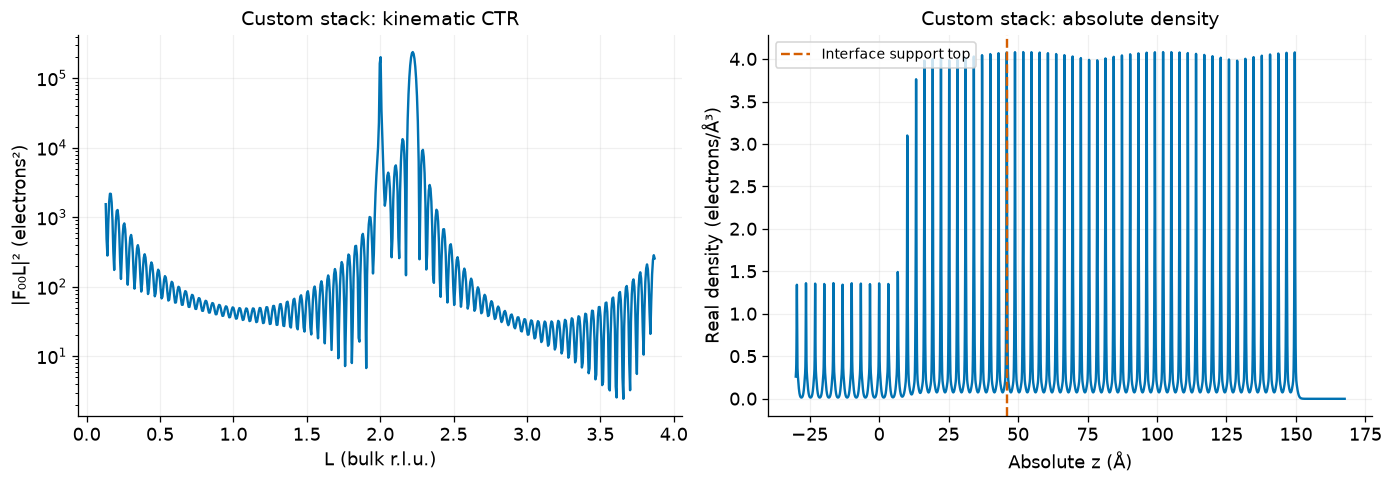

In [9]:
custom_model = make_model(
    positions=(0.0, 0.5), film_width=48, interface_width=0.5,
    registry_layers=3, coupling=0.7, mismatch=0.9, offset=0.1,
)
custom_skew = 0.2
set_skew(custom_model, custom_skew)
custom_z_A = np.linspace(-30.0, max(130.0, custom_model["film"].height_absolute + 15), 6401)
custom_geometry, custom_f, custom_density = sample(custom_model, custom_skew, H, K, L, custom_z_A)
display(pd.DataFrame([custom_geometry]))
print("Interface order:", custom_model["interface"].layer_order)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.1), layout="constrained")
axes[0].semilogy(L, np.abs(custom_f) ** 2, color=COLORS[0])
axes[0].set(xlabel="L (bulk r.l.u.)", ylabel="|F₀₀L|² (electrons²)", title="Custom stack: kinematic CTR")
axes[1].plot(custom_z_A, custom_density, color=COLORS[0])
axes[1].axvline(custom_geometry["interface top (Å)"], color=COLORS[1], linestyle="--", label="Interface support top")
axes[1].set(xlabel="Absolute z (Å)", ylabel="Real density (electrons/Å³)", title="Custom stack: absolute density")
axes[1].legend()
plt.show()

### What these results establish

- The zero-skew cyclic-anchor example retains all expected Film layers.
- The lower-reference threshold has no finite geometry, complex-F, or density jump.
- Exact threshold values agree with the limiting calculations.
- Enlarging support changes component ownership while predictions converge.

Finite changes in skew, strain coupling, lattice mismatch, or offset can still
change the physical prediction. Saved fits made with the previous anchor or
subtraction behavior should be recomputed and reassessed.

For the coordinate contract, see the repository's
[CTR guide](../../doc/source/ctr_structure_factors.rst) and
[two-stage implementation record](../../doc/design/epitaxy_interface_anchor_implementation_plan.md).